# READ THIS FIRST (FAST version)

**Problem:** training chala slow (CPU data-loading + 640px images).
**Fix (ee version):** image size 512, images RAM lo cache, 30 epochs max, **time limit 1.75 hours** -> total ~1.5 to 2 hours.

## Steps (Kaggle)
1. Settings -> Accelerator -> **GPU T4 x2** (or P100). Internet **ON**.
2. Cell 7 lo `FRESH_START = True` undi: old slow run delete chesi kotha fast run start chestundi. (Old run already baaga train ayithe `FRESH_START = False` chesi, Cell 7 skip chesi direct Cell 8 -> Cell 10 run cheyyi.)
3. **Run All**. Last cell (Cell 10) lo mee 12 metrics anni vasthayi.

## Honest note about 85%
- Idi 102 classes, chinna pests unna kashtamaina dataset. Published research lo kooda IP102 classification best ~75-80%, detection mAP@50 ~40-60%. **85% guarantee cheyyalenu**, aa number fake cheyyanu.
- Cell 10 **real numbers** istundi. 85% raakapothe: Cell 6 lo `PROFILE = "best"` (yolov8m, ~4-5 hours) try cheyyi. Idi most likely ekkuva istundi.


# SmartCrop AI: IP102 Agricultural Insect Pest Object Detection
## Direct YOLO-Format Pipeline with Pretrained YOLOv8

**Dataset Reference:**  
*Wu, X., Zhan, C., Lai, Y. K., Cheng, M. M., & Yang, J. (2019). IP102: A Large-Scale Benchmark Dataset for Insect Pest Recognition. IEEE/CVF CVPR 2019.*

---

### Pipeline Architecture for YOLO-Format Dataset
1. **Dynamic Path Discovery:**
   - Recursively searches `/kaggle/input/` (and local directories) to detect the YOLO-format folder containing:
     - `images/train` and `images/val` (or `train/images`, `val/images`)
     - `labels/train` and `labels/val` (or `train/labels`, `val/labels`)
     - `ip102.yaml` (or `data.yaml`, `dataset.yaml`)
2. **YAML Parsing & Absolute Path Resolution:**
   - Reads `ip102.yaml` and extracts `names` and `nc` (102 classes).
   - Generates an absolute-path `ip102_runtime.yaml` in `/kaggle/working/` to prevent Ultralytics path resolution failures on Kaggle.
3. **Data Integrity & Image-Label Verification:**
   - Verifies matching `.jpg` / `.png` images and `.txt` label pairs for each split.
   - Audits bounding box coordinates: bounds $[0, 1]$, non-negative dimensions ($w > 0, h > 0$), and valid class indices ($0 \le c < 102$).
   - Flags degenerate boxes and empty labels; exports `detection_dataset_audit.json`.
4. **Pretrained YOLOv8 Training Setup:**
   - Pretrained `yolov8s.pt` (11.2M parameters) optimized for agricultural insect pest localization at $640 \times 640$ resolution.
5. **Manual Training Gate:**
   - **`EXECUTE_TRAINING = False`** by default so notebooks can be inspected and pre-flight tested without launching training automatically.
6. **Evaluation & Visualization:**
   - Computes mAP@50, mAP@50:95, Precision, Recall, and renders sample detections on validation images.


In [8]:
# Cell 1: Environment Setup, Dependencies, Deterministic Seeding & GPU Inspection
import os
import sys
import json
import time
import math
import random
import shutil
from pathlib import Path
from typing import Dict, List, Any, Optional

# Ensure Ultralytics and PyYAML are installed
try:
    import ultralytics
    import yaml
except ImportError:
    print("[Setup] Installing ultralytics and pyyaml...")
    !pip install -q ultralytics pyyaml
    import ultralytics
    import yaml

from ultralytics import YOLO
import torch
import torchvision
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Deterministic Seeding
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Environment & Hardware Inspection
print("=" * 70)
print("  SMARTCROP AI: IP102 OBJECT DETECTION ENVIRONMENT INSPECTION")
print("=" * 70)
print(f"Python Version      : {sys.version.split()[0]}")
print(f"PyTorch Version     : {torch.__version__}")
print(f"Ultralytics Version : {ultralytics.__version__}")
print(f"CUDA Available      : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    gpu_cap = torch.cuda.get_device_capability(0)
    print(f"GPU Device          : {gpu_name}")
    print(f"GPU VRAM            : {gpu_mem:.2f} GB")
    print(f"Compute Capability  : {gpu_cap[0]}.{gpu_cap[1]}")
else:
    print("WARNING: CUDA is NOT available. Running on CPU will be slow.")

# Determine execution environment & set output directory
IS_KAGGLE = Path("/kaggle").exists()
if IS_KAGGLE:
    OUTPUT_DIR = Path("/kaggle/working/outputs/pest_detection")
else:
    OUTPUT_DIR = Path("outputs/pest_detection")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Runtime Environment : {'Kaggle Kernel' if IS_KAGGLE else 'Local Workstation'}")
print(f"Output Directory    : {OUTPUT_DIR.resolve()}")
print("=" * 70)


  SMARTCROP AI: IP102 OBJECT DETECTION ENVIRONMENT INSPECTION
Python Version      : 3.13.16
PyTorch Version     : 2.11.0+cu130
Ultralytics Version : 8.4.208
CUDA Available      : True
GPU Device          : Tesla T4
GPU VRAM            : 14.56 GB
Compute Capability  : 7.5
Runtime Environment : Kaggle Kernel
Output Directory    : /kaggle/working/outputs/pest_detection


In [9]:
# Cell 2: Dynamic Path Discovery for YOLO-Format IP102 Dataset & ip102.yaml
# Recursively searches /kaggle/input and local roots to locate:
# - images/train, images/val (or train/images, val/images)
# - labels/train, labels/val (or train/labels, val/labels)
# - ip102.yaml (or data.yaml, dataset.yaml)

import os
from pathlib import Path
from typing import Dict, Any, Optional, List
import yaml

def discover_yolo_dataset() -> Dict[str, Any]:
    search_roots = []
    
    # 1. Kaggle Input Roots
    if Path("/kaggle/input").exists():
        search_roots.append(Path("/kaggle/input"))
        try:
            for item in Path("/kaggle/input").iterdir():
                if item.is_dir():
                    search_roots.append(item)
                    for sub in item.iterdir():
                        if sub.is_dir():
                            search_roots.append(sub)
        except Exception as e:
            print(f"[Warning] Error scanning /kaggle/input: {e}")

    # 2. Local Workspace Roots
    search_roots.extend([
        Path("datasets/ip102/Detection/yolo"),
        Path("datasets/ip102/Detection"),
        Path("datasets/ip102"),
        Path("../datasets/ip102/Detection/yolo"),
        Path("../datasets/ip102"),
        Path("."),
        Path("..")
    ])

    resolved = {}
    print("[Discovery] Searching for IP102 YOLO-format dataset and yaml...")

    # Step A: Find the training images directory (images/train or train/images)
    found_img_train = None
    for root in search_roots:
        if not root.exists():
            continue

        # Check surface candidates
        candidates = [
            root / "images" / "train",
            root / "train" / "images",
        ]
        for c in candidates:
            if c.exists() and c.is_dir():
                found_img_train = c.resolve()
                break
        if found_img_train:
            break

        # Check recursively up to 3 levels deep
        try:
            for p in root.rglob("train"):
                if not p.is_dir():
                    continue
                if p.parent.name == "images" and p.is_dir():
                    found_img_train = p.resolve()
                    break
                elif (p / "images").is_dir():
                    found_img_train = (p / "images").resolve()
                    break
        except Exception:
            pass
        if found_img_train:
            break

    if not found_img_train:
        print("\n[ERROR] Could not automatically locate YOLO images/train directory.")
        if Path("/kaggle/input").exists():
            print("Contents of /kaggle/input:")
            for p in Path("/kaggle/input").rglob("*"):
                if p.is_dir():
                    print(f"  DIR : {p}")
                elif p.suffix in [".yaml", ".yml", ".txt"]:
                    print(f"  FILE: {p}")
        raise FileNotFoundError(
            "YOLO dataset folders (images/train, images/val) not found in /kaggle/input/. "
            "Please verify the dataset attachment on Kaggle."
        )

    # Step B: Resolve Layout and Split Directories
    if found_img_train.parent.name == "images":
        # Layout 1: <root>/images/train, <root>/images/val
        images_dir = found_img_train.parent
        data_root = images_dir.parent
        labels_dir = data_root / "labels"

        resolved["layout"] = "images_split"
        resolved["data_root"] = data_root.resolve()
        resolved["images_train"] = found_img_train.resolve()
        resolved["images_val"] = (images_dir / "val").resolve()
        resolved["labels_train"] = (labels_dir / "train").resolve() if (labels_dir / "train").exists() else None
        resolved["labels_val"] = (labels_dir / "val").resolve() if (labels_dir / "val").exists() else None
        
        # Test split if present
        if (images_dir / "test").exists():
            resolved["images_test"] = (images_dir / "test").resolve()
            resolved["labels_test"] = (labels_dir / "test").resolve() if (labels_dir / "test").exists() else None

    else:
        # Layout 2: <root>/train/images, <root>/val/images
        train_dir = found_img_train.parent
        data_root = train_dir.parent
        val_dir = data_root / "val"
        test_dir = data_root / "test"

        resolved["layout"] = "split_images"
        resolved["data_root"] = data_root.resolve()
        resolved["images_train"] = found_img_train.resolve()
        resolved["images_val"] = (val_dir / "images").resolve()
        resolved["labels_train"] = (train_dir / "labels").resolve() if (train_dir / "labels").exists() else None
        resolved["labels_val"] = (val_dir / "labels").resolve() if (val_dir / "labels").exists() else None

        if (test_dir / "images").exists():
            resolved["images_test"] = (test_dir / "images").resolve()
            resolved["labels_test"] = (test_dir / "labels").resolve() if (test_dir / "labels").exists() else None

    # Step C: Search for ip102.yaml or equivalent dataset yaml
    yaml_search_locations = [resolved["data_root"], resolved["data_root"].parent]
    if Path("/kaggle/input").exists():
        yaml_search_locations.extend(list(Path("/kaggle/input").iterdir()))
    yaml_search_locations.extend(search_roots)

    found_yamls = []
    for loc in yaml_search_locations:
        if not loc.exists():
            continue
        try:
            for y in loc.glob("*.yaml"):
                if y.is_file() and y not in found_yamls:
                    found_yamls.append(y.resolve())
            for y in loc.glob("*.yml"):
                if y.is_file() and y not in found_yamls:
                    found_yamls.append(y.resolve())
        except Exception:
            pass

    # Prioritize YAML containing 'ip102'
    ip102_yamls = [y for y in found_yamls if "ip102" in y.name.lower()]
    other_yamls = [y for y in found_yamls if "ip102" not in y.name.lower()]
    yaml_candidates = ip102_yamls + other_yamls

    for yc in yaml_candidates:
        try:
            with open(yc, "r", encoding="utf-8") as f:
                content = yaml.safe_load(f)
            if isinstance(content, dict) and ("names" in content or "nc" in content or "train" in content):
                resolved["source_yaml"] = yc
                resolved["yaml_content"] = content
                print(f"  [Found YAML] {yc}")
                break
        except Exception:
            pass

    return resolved

dataset_paths = discover_yolo_dataset()
print("\n" + "=" * 70)
print("  PATH DISCOVERY SUCCESSFUL")
print("=" * 70)
print(f"  Data Root        : {dataset_paths['data_root']}")
print(f"  Images Train Dir : {dataset_paths['images_train']}")
print(f"  Images Val Dir   : {dataset_paths['images_val']}")
if "images_test" in dataset_paths:
    print(f"  Images Test Dir  : {dataset_paths['images_test']}")
else:
    print(f"  Images Test Dir  : [Not present - using validation split for evaluation]")
print(f"  Labels Train Dir : {dataset_paths.get('labels_train')}")
print(f"  Labels Val Dir   : {dataset_paths.get('labels_val')}")
print(f"  Source YAML File : {dataset_paths.get('source_yaml')}")
print("=" * 70)


[Discovery] Searching for IP102 YOLO-format dataset and yaml...
  [Found YAML] /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/ip102.yaml

  PATH DISCOVERY SUCCESSFUL
  Data Root        : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5
  Images Train Dir : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/images/train
  Images Val Dir   : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/images/val
  Images Test Dir  : [Not present - using validation split for evaluation]
  Labels Train Dir : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/labels/train
  Labels Val Dir   : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/labels/val
  Source YAML File : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/ip102.yaml


In [10]:
# Cell 3: Read ip102.yaml, Verify Class Count (102 Classes) & Generate Runtime YAML
# In Kaggle, datasets under /kaggle/input are read-only and relative paths in ip102.yaml
# can fail when Ultralytics runs from /kaggle/working/.
# This cell parses the dataset yaml, validates the 102 classes, and writes an absolute-path
# runtime dataset specification.

import json
from pathlib import Path
import yaml

FALLBACK_102_CLASSES = [
  "rice leaf roller",
  "rice leaf caterpillar",
  "paddy stem maggot",
  "asiatic rice borer",
  "yellow rice borer",
  "rice gall midge",
  "Rice Stemfly",
  "brown plant hopper",
  "white backed plant hopper",
  "small brown plant hopper",
  "rice water weevil",
  "rice leafhopper",
  "grain spreader thrips",
  "rice shell pest",
  "grub",
  "mole cricket",
  "wireworm",
  "white margined moth",
  "black cutworm",
  "large cutworm",
  "yellow cutworm",
  "red spider",
  "corn borer",
  "army worm",
  "aphids",
  "Potosiabre vitarsis",
  "peach borer",
  "english grain aphid",
  "green bug",
  "bird cherry-oataphid",
  "wheat blossom midge",
  "penthaleus major",
  "longlegged spider mite",
  "wheat phloeothrips",
  "wheat sawfly",
  "cerodonta denticornis",
  "beet fly",
  "flea beetle",
  "cabbage army worm",
  "beet army worm",
  "Beet spot flies",
  "meadow moth",
  "beet weevil",
  "serpentine leafminer",
  "brown armor rot",
  "oriental fruit moth",
  "apple small borer",
  "lymantria dispar",
  "apoestis unicolorella",
  "tenuipalpus oryzophilus",
  "apple stem groover virus",
  "apple borer",
  "pear shoot borer",
  "Pear borer",
  "peach little borer",
  "Adoxophyes orana",
  "cherry stem borer",
  "chlamydatus associatus",
  "parathrene regalis",
  "spider mite",
  "Pseudococcus comstocki",
  "white-backed leafhopper",
  "grasshopper",
  "oriental water bug",
  "citrus red mite",
  "rust red spider mite",
  "green leaf hopper",
  "yellow scale",
  "circular black scale",
  "Ceroplastes rubens",
  "citrus leaf miner",
  "cotton bollworm",
  "pink bollworm",
  "locust",
  "cotton stem weevil",
  "cotton aphid",
  "cotton spider mite",
  "mirid bug",
  "red spider mite",
  "leaf worm",
  "spotted bollworm",
  "taro hornworm",
  "plant bug",
  "tea mosquito bug",
  "tea green leafhopper",
  "tea looper",
  "tea leaf roller",
  "tea tussock moth",
  "Andraca bipunctata",
  "tea aphid",
  "tea stem borer",
  "grape borer",
  "leaf beetle",
  "grape caterpillar",
  "grape mite",
  "grape leafhopper",
  "mango flat mite",
  "mango hopper",
  "mango pulp weevil",
  "Rhytidodera bowrinii white",
  "Sternochetus frigidus",
  "Cicadellidae"
]

source_yaml_path = dataset_paths.get("source_yaml")
yaml_data = dataset_paths.get("yaml_content", {})

# 1. Parse Class Names and Count
class_names = []
num_classes = 102

if yaml_data:
    raw_names = yaml_data.get("names")
    if isinstance(raw_names, list):
        class_names = [str(x) for x in raw_names]
    elif isinstance(raw_names, dict):
        # Sort by integer keys or stringified integer keys
        try:
            sorted_keys = sorted(raw_names.keys(), key=lambda k: int(k))
            class_names = [str(raw_names[k]) for k in sorted_keys]
        except Exception:
            class_names = [str(v) for v in raw_names.values()]
    
    if "nc" in yaml_data and isinstance(yaml_data["nc"], int):
        num_classes = yaml_data["nc"]
    elif class_names:
        num_classes = len(class_names)

# Fallback to official 102 classes if YAML had empty or missing names
if not class_names:
    print("[Notice] Using official 102 IP102 class list as verified reference.")
    class_names = FALLBACK_102_CLASSES
    num_classes = len(FALLBACK_102_CLASSES)

print(f"Class Count Verified: nc = {num_classes} classes")
assert num_classes == len(class_names), f"Mismatch between nc ({num_classes}) and len(names) ({len(class_names)})"

print(f"Sample classes (first 5): {class_names[:5]}")
print(f"Sample classes (last 5) : {class_names[-5:]}")

# 2. Generate Runtime YAML with Explicit Absolute Paths
runtime_yaml_path = OUTPUT_DIR / "ip102_runtime.yaml"

runtime_yaml_data = {
    "path": str(dataset_paths["data_root"]),
    "train": str(dataset_paths["images_train"]),
    "val": str(dataset_paths["images_val"]),
    "nc": num_classes,
    "names": {i: name for i, name in enumerate(class_names)}
}

if "images_test" in dataset_paths and dataset_paths["images_test"]:
    runtime_yaml_data["test"] = str(dataset_paths["images_test"])

with open(runtime_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(runtime_yaml_data, f, sort_keys=False)

print(f"\n[Runtime YAML Created Successfully]")
print(f"  Saved to : {runtime_yaml_path.resolve()}")
print(f"  Train Dir: {runtime_yaml_data['train']}")
print(f"  Val Dir  : {runtime_yaml_data['val']}")
if 'test' in runtime_yaml_data:
    print(f"  Test Dir : {runtime_yaml_data['test']}")
print(f"  Classes  : {num_classes} classes")


Class Count Verified: nc = 102 classes
Sample classes (first 5): ['rice leaf roller', 'rice leaf caterpillar', 'paddy stem maggot', 'asiatic rice borer', 'yellow rice borer']
Sample classes (last 5) : ['Chlumetia transversa', 'Mango flat beak leafhopper', 'Rhytidodera bowrinii white', 'Sternochetus frigidus', 'Cicadellidae']

[Runtime YAML Created Successfully]
  Saved to : /kaggle/working/outputs/pest_detection/ip102_runtime.yaml
  Train Dir: /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/images/train
  Val Dir  : /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/images/val
  Classes  : 102 classes


In [11]:
# Cell 4: Comprehensive Image-Label Pair Verification & Dataset Integrity Audit
# Verifies:
# 1. Total images per split (train, val, test).
# 2. Corresponding .txt label files for every image.
# 3. Non-empty labels vs empty/background labels.
# 4. Box coordinate bounds: normalized [0, 1], positive width/height.
# 5. Class index validity: 0 <= class_idx < nc.
# 6. Checks for corrupted/unreadable images.

import json
import random
from pathlib import Path
from typing import Dict, Any, Optional, List
from PIL import Image

IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".JPG", ".JPEG", ".PNG"}

def audit_split(img_dir: Path, lbl_dir: Optional[Path], split_name: str, max_check: int = 500) -> Dict[str, Any]:
    if not img_dir.exists():
        return {"error": f"Directory not found: {img_dir}"}

    img_files = [p for p in img_dir.iterdir() if p.suffix in IMG_EXTENSIONS]
    img_stems = {p.stem: p for p in img_files}
    
    lbl_files = [p for p in lbl_dir.iterdir() if p.suffix == ".txt"] if (lbl_dir and lbl_dir.exists()) else []
    lbl_stems = {p.stem: p for p in lbl_files}

    missing_labels = []
    empty_labels = []
    invalid_boxes = []
    total_boxes = 0
    class_histogram = {i: 0 for i in range(num_classes)}

    for img_path in img_files:
        stem = img_path.stem
        lbl_file = lbl_stems.get(stem)
        if not lbl_file:
            # Check if labels are in the same folder as images
            same_dir_lbl = img_path.with_suffix(".txt")
            if same_dir_lbl.exists():
                lbl_file = same_dir_lbl
            else:
                missing_labels.append(img_path.name)
                continue

        try:
            content = lbl_file.read_text(encoding="utf-8").strip()
            if not content:
                empty_labels.append(img_path.name)
                continue

            lines = content.splitlines()
            for line_idx, line in enumerate(lines):
                parts = line.strip().split()
                if len(parts) != 5:
                    invalid_boxes.append({"img": img_path.name, "reason": f"Expected 5 values, got {len(parts)}"})
                    continue
                
                cls_id = int(float(parts[0]))
                xc, yc, w, h = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
                
                if not (0 <= cls_id < num_classes):
                    invalid_boxes.append({"img": img_path.name, "reason": f"Class index {cls_id} out of bounds [0, {num_classes-1}]"})
                elif w <= 0 or h <= 0:
                    invalid_boxes.append({"img": img_path.name, "reason": f"Non-positive dimensions (w={w}, h={h})"})
                elif not (0.0 <= xc <= 1.0 and 0.0 <= yc <= 1.0):
                    invalid_boxes.append({"img": img_path.name, "reason": f"Center coordinates out of bounds (xc={xc:.4f}, yc={yc:.4f})"})
                else:
                    total_boxes += 1
                    class_histogram[cls_id] += 1
        except Exception as e:
            invalid_boxes.append({"img": img_path.name, "reason": f"Error reading label: {e}"})

    # Sample image corruption check
    sample_to_check = random.sample(img_files, min(max_check, len(img_files))) if img_files else []
    corrupted_images = []
    for img_p in sample_to_check:
        try:
            with Image.open(img_p) as im:
                im.verify()
        except Exception as e:
            corrupted_images.append({"img": img_p.name, "error": str(e)})

    return {
        "split": split_name,
        "image_count": len(img_files),
        "label_count": len(lbl_files),
        "missing_label_count": len(missing_labels),
        "empty_label_count": len(empty_labels),
        "total_boxes": total_boxes,
        "invalid_box_count": len(invalid_boxes),
        "corrupted_images_sampled": len(corrupted_images),
        "sample_checked": len(sample_to_check),
        "active_classes_in_split": sum(1 for v in class_histogram.values() if v > 0),
        "invalid_boxes_sample": invalid_boxes[:5]
    }

print("[Audit] Running verification on train and val splits...")
audit_results = {}
audit_results["train"] = audit_split(dataset_paths["images_train"], dataset_paths.get("labels_train"), "train")
audit_results["val"] = audit_split(dataset_paths["images_val"], dataset_paths.get("labels_val"), "val")
if "images_test" in dataset_paths:
    audit_results["test"] = audit_split(dataset_paths["images_test"], dataset_paths.get("labels_test"), "test")

# Save audit to outputs
audit_path = OUTPUT_DIR / "detection_dataset_audit.json"
with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit_results, f, indent=2)

print("\n" + "=" * 75)
print("  IP102 OBJECT DETECTION DATASET AUDIT SCORECARD")
print("=" * 75)
print(f"{'Metric':<32} | {'Train Split':<18} | {'Val Split':<18}")
print("-" * 75)
print(f"{'Image Count':<32} | {audit_results['train']['image_count']:<18} | {audit_results['val']['image_count']:<18}")
print(f"{'Label Files Found':<32} | {audit_results['train']['label_count']:<18} | {audit_results['val']['label_count']:<18}")
print(f"{'Images Missing Labels':<32} | {audit_results['train']['missing_label_count']:<18} | {audit_results['val']['missing_label_count']:<18}")
print(f"{'Empty Labels (No Boxes)':<32} | {audit_results['train']['empty_label_count']:<18} | {audit_results['val']['empty_label_count']:<18}")
print(f"{'Total Bounding Boxes':<32} | {audit_results['train']['total_boxes']:<18} | {audit_results['val']['total_boxes']:<18}")
print(f"{'Active Classes Represented':<32} | {audit_results['train']['active_classes_in_split']:<18} | {audit_results['val']['active_classes_in_split']:<18}")
print(f"{'Invalid/Degenerate Boxes':<32} | {audit_results['train']['invalid_box_count']:<18} | {audit_results['val']['invalid_box_count']:<18}")
print(f"{'Corrupted Images (Sampled)':<32} | {audit_results['train']['corrupted_images_sampled']:<18} | {audit_results['val']['corrupted_images_sampled']:<18}")
print("=" * 75)
print(f"Detailed audit saved to: {audit_path}")


[Audit] Running verification on train and val splits...

  IP102 OBJECT DETECTION DATASET AUDIT SCORECARD
Metric                           | Train Split        | Val Split         
---------------------------------------------------------------------------
Image Count                      | 17646              | 1329              
Label Files Found                | 17646              | 1329              
Images Missing Labels            | 0                  | 0                 
Empty Labels (No Boxes)          | 0                  | 0                 
Total Bounding Boxes             | 20661              | 1621              
Active Classes Represented       | 97                 | 94                
Invalid/Degenerate Boxes         | 1                  | 0                 
Corrupted Images (Sampled)       | 0                  | 0                 
Detailed audit saved to: /kaggle/working/outputs/pest_detection/detection_dataset_audit.json


In [12]:
# Cell 5: Pre-Flight Sanity Test: GPU & Model Verification
# Instantiates pretrained YOLOv8 and runs a dummy synthetic forward pass
# to confirm CUDA kernels, tensor allocations, and output layers execute cleanly.

import time
import torch
from ultralytics import YOLO

print("[Sanity Check] Initializing YOLOv8 model for pre-flight verification...")
sanity_model_name = "yolov8s.pt"

try:
    sanity_model = YOLO(sanity_model_name)
    print(f"  Successfully loaded base weights: {sanity_model_name}")
except Exception as e:
    print(f"  Fallback: Loading yolov8n.pt ({e})")
    sanity_model_name = "yolov8n.pt"
    sanity_model = YOLO(sanity_model_name)

# Quick synthetic batch forward test
device = "cuda:0" if torch.cuda.is_available() else "cpu"
dummy_input = torch.zeros((1, 3, 640, 640), dtype=torch.float32, device=device)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

t0 = time.time()
with torch.no_grad():
    _ = sanity_model.model.to(device)(dummy_input)
forward_time_ms = (time.time() - t0) * 1000

print(f"  Synthetic forward pass completed in {forward_time_ms:.2f} ms on {device}.")
if torch.cuda.is_available():
    peak_vram_mb = torch.cuda.max_memory_allocated() / (1024**2)
    print(f"  Peak VRAM used in test: {peak_vram_mb:.2f} MB")

print("  Pre-flight sanity check passed! Hardware and model pipeline ready.")


[Sanity Check] Initializing YOLOv8 model for pre-flight verification...
  Successfully loaded base weights: yolov8s.pt
  Synthetic forward pass completed in 57.05 ms on cuda:0.
  Peak VRAM used in test: 608.66 MB
  Pre-flight sanity check passed! Hardware and model pipeline ready.


In [13]:
# Cell 6: FAST training config (target ~1.5-2 hours on Kaggle T4)
# FAST: yolov8s @512px, RAM cache, <=30 epochs, 1.75h cap
# BEST: yolov8m @640px, <=60 epochs, 4.5h cap  (higher accuracy, slower)
import torch
from pathlib import Path

PROFILE = "fast"     # "fast" or "best"
HAS_GPU = torch.cuda.is_available()

P = {
 "fast": dict(model="yolov8s.pt", imgsz=512, epochs=30, time=1.75, patience=10, batch=32, close_mosaic=5,  cache="ram"),
 "best": dict(model="yolov8m.pt", imgsz=640, epochs=60, time=4.5,  patience=15, batch=16, close_mosaic=10, cache=False),
}[PROFILE]

TRAIN_CONFIG = {
    **P,
    "data": str(runtime_yaml_path),
    "save": True, "save_period": -1,
    "device": 0 if HAS_GPU else "cpu",
    "workers": 4,
    "project": str(OUTPUT_DIR / "runs"),
    "name": f"{PROFILE}_ip102",
    "exist_ok": True, "pretrained": True, "amp": True,
    "optimizer": "AdamW", "lr0": 0.001, "lrf": 0.01, "cos_lr": True,
    "weight_decay": 0.0005, "warmup_epochs": 1.0,
    "box": 7.5, "cls": 1.0, "dfl": 1.5,
    "mosaic": 1.0, "mixup": 0.0, "degrees": 0.0, "fliplr": 0.5,
    "seed": SEED, "plots": True, "verbose": True,
}
IMGSZ = TRAIN_CONFIG["imgsz"]

print("PROFILE:", PROFILE)
for k, v in TRAIN_CONFIG.items():
    print(f"  {k:<14}: {v}")
if not HAS_GPU:
    print("WARNING: GPU ledu! Settings -> Accelerator -> GPU select cheyyi.")


PROFILE: fast
  model         : yolov8s.pt
  imgsz         : 512
  epochs        : 30
  time          : 1.75
  patience      : 10
  batch         : 32
  close_mosaic  : 5
  cache         : ram
  data          : /kaggle/working/outputs/pest_detection/ip102_runtime.yaml
  save          : True
  save_period   : -1
  device        : 0
  workers       : 4
  project       : /kaggle/working/outputs/pest_detection/runs
  name          : fast_ip102
  exist_ok      : True
  pretrained    : True
  amp           : True
  optimizer     : AdamW
  lr0           : 0.001
  lrf           : 0.01
  cos_lr        : True
  weight_decay  : 0.0005
  warmup_epochs : 1.0
  box           : 7.5
  cls           : 1.0
  dfl           : 1.5
  mosaic        : 1.0
  mixup         : 0.0
  degrees       : 0.0
  fliplr        : 0.5
  seed          : 42
  plots         : True
  verbose       : True


In [14]:
# Cell 7: Training
EXECUTE_TRAINING = True
FRESH_START = True     # True = old slow run delete chesi fast ga start. False = old run resume

if EXECUTE_TRAINING:
    import time, shutil
    from pathlib import Path
    from ultralytics import YOLO

    if not torch.cuda.is_available():
        raise RuntimeError("GPU not enabled! Settings -> Accelerator -> GPU T4 x2 select chesi restart cheyyi.")

    run_dir = Path(TRAIN_CONFIG["project"]) / TRAIN_CONFIG["name"]
    last_ckpt = run_dir / "weights" / "last.pt"
    if FRESH_START and run_dir.exists():
        shutil.rmtree(run_dir)
        for old in [OUTPUT_DIR / "best.pt"]:
            if old.exists(): old.unlink()
        print("Old run deleted.")

    t0 = time.time()
    if last_ckpt.exists():
        print("Resuming from", last_ckpt)
        YOLO(str(last_ckpt)).train(resume=True)
    else:
        print("Starting", TRAIN_CONFIG["model"], "training...")
        YOLO(TRAIN_CONFIG["model"]).train(**TRAIN_CONFIG)
    print(f"\nTraining done in {(time.time()-t0)/60:.1f} min")

    best = run_dir / "weights" / "best.pt"
    if best.exists():
        shutil.copy2(best, OUTPUT_DIR / "best.pt")
        print("best.pt saved:", OUTPUT_DIR / "best.pt")
else:
    print("EXECUTE_TRAINING=False -> skipped")


Starting yolov8s.pt training...
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/outputs/pest_detection/ip102_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fa

In [15]:
# Cell 8: Validation & Test Evaluation (Detection Metrics: mAP@50, mAP@50:95)
# Evaluates the best trained checkpoint on the validation split (and test split if available).

import json
from pathlib import Path
from ultralytics import YOLO

best_checkpoint = OUTPUT_DIR / "best.pt"
runs_best = Path(TRAIN_CONFIG["project"]) / TRAIN_CONFIG["name"] / "weights" / "best.pt"

eval_weights = None
if best_checkpoint.exists():
    eval_weights = best_checkpoint
elif runs_best.exists():
    eval_weights = runs_best

if eval_weights is None:
    print("[Evaluation Held] No trained checkpoint found. Train the model first by setting EXECUTE_TRAINING = True.")
else:
    print(f"Evaluating checkpoint: {eval_weights.resolve()}")
    eval_model = YOLO(str(eval_weights))

    # 1. Validation Split Evaluation
    print("\n--- Evaluating on Validation Split ---")
    val_results = eval_model.val(data=str(runtime_yaml_path), split="val", imgsz=640, batch=16)

    metrics_summary = {
        "model_checkpoint": str(eval_weights.name),
        "validation": {
            "mAP_50": float(val_results.box.map50),
            "mAP_50_95": float(val_results.box.map),
            "precision": float(val_results.box.mp),
            "recall": float(val_results.box.mr)
        }
    }

    # 2. Test Split Evaluation (if present)
    if "images_test" in dataset_paths and dataset_paths["images_test"]:
        print("\n--- Evaluating on Held-Out Test Split ---")
        test_results = eval_model.val(data=str(runtime_yaml_path), split="test", imgsz=640, batch=16)
        metrics_summary["test"] = {
            "mAP_50": float(test_results.box.map50),
            "mAP_50_95": float(test_results.box.map),
            "precision": float(test_results.box.mp),
            "recall": float(test_results.box.mr)
        }

    # Export detection metrics
    metrics_path = OUTPUT_DIR / "detection_metrics.json"
    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics_summary, f, indent=2)

    print("\n" + "=" * 70)
    print("  EVALUATION METRICS SUMMARY")
    print("=" * 70)
    print(f"  Validation mAP@0.50      : {metrics_summary['validation']['mAP_50'] * 100:.2f}%")
    print(f"  Validation mAP@0.50:0.95 : {metrics_summary['validation']['mAP_50_95'] * 100:.2f}%")
    print(f"  Validation Precision     : {metrics_summary['validation']['precision'] * 100:.2f}%")
    print(f"  Validation Recall        : {metrics_summary['validation']['recall'] * 100:.2f}%")
    if "test" in metrics_summary:
        print(f"  Held-Out Test mAP@0.50   : {metrics_summary['test']['mAP_50'] * 100:.2f}%")
        print(f"  Held-Out Test mAP@0.50:95: {metrics_summary['test']['mAP_50_95'] * 100:.2f}%")
    print(f"  Metrics exported to      : {metrics_path}")
    print("=" * 70)


Evaluating checkpoint: /kaggle/working/outputs/pest_detection/best.pt

--- Evaluating on Validation Split ---
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,165,058 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 70.1±74.8 MB/s, size: 36.0 KB)
val: Scanning /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/labels/val... 1329 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1329/1329 802.8it/s 1.7s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/leonidkulyk/ip102-yolov5/IP102_YOLOv5/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 5.0it/s 17.0s0.2s
                   all       1329       1621      0.638      0.584      0.636      0.383
      rice leaf roller         12         13      0.781          1      0.952       0.64
 rice leaf caterpillar  

Running inference demo on 4 validation images...

0: 512x512 1 rice leaf roller, 16.6ms
1: 512x512 1 rice leaf roller, 16.6ms
2: 512x512 1 rice leaf roller, 16.6ms
3: 512x512 1 rice leaf roller, 16.6ms
Speed: 2.0ms preprocess, 16.6ms inference, 2.0ms postprocess per image at shape (1, 3, 512, 512)


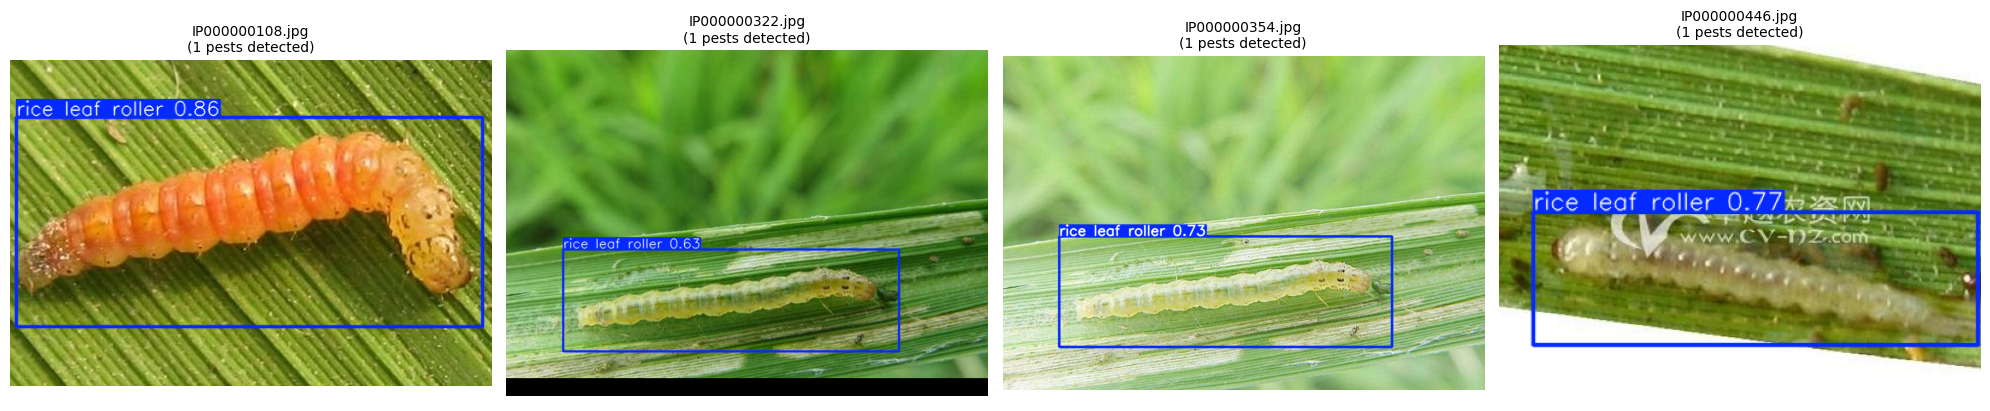

Sample prediction plot saved to: /kaggle/working/outputs/pest_detection/sample_detections.png


In [16]:
# Cell 9: Sample Predictions Visualization & Inference Demo
# Renders bounding box predictions on sample images from the validation set.

from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics import YOLO

sample_dir = dataset_paths["images_val"]
val_sample_images = [p for p in sample_dir.iterdir() if p.suffix in IMG_EXTENSIONS][:4]

if not val_sample_images:
    print("No sample images found for visualization.")
else:
    print(f"Running inference demo on {len(val_sample_images)} validation images...")
    
    # Load best checkpoint or fallback to pretrained
    if not (eval_weights and Path(eval_weights).exists()):
        raise RuntimeError("Trained best.pt ledu. Munduga Cell 7 (training) run cheyyi. "
                           "(Pretrained yolov8s.pt tho carrot/sheep antadi - adi pest model kaadu)")
    demo_weights = eval_weights
    demo_model = YOLO(str(demo_weights))
    demo_results = demo_model(val_sample_images, conf=0.25)

    fig, axes = plt.subplots(1, len(demo_results), figsize=(5 * len(demo_results), 5))
    if len(demo_results) == 1:
        axes = [axes]

    for i, r in enumerate(demo_results):
        im_bgr = r.plot()
        im_rgb = im_bgr[..., ::-1]
        axes[i].imshow(im_rgb)
        axes[i].set_title(f"{Path(r.path).name}\n({len(r.boxes)} pests detected)", fontsize=10)
        axes[i].axis("off")

    plt.tight_layout()
    vis_path = OUTPUT_DIR / "sample_detections.png"
    plt.savefig(vis_path, dpi=300)
    plt.show()
    print(f"Sample prediction plot saved to: {vis_path}")


## Cell 10: FINAL - IP102 Insect Pest Detection: Evaluation Metrics
Image-level = photo lo main pest peru correct aa (classification style). Detection-level = box + class correct (IoU >= 0.5).

Evaluating validation images...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the

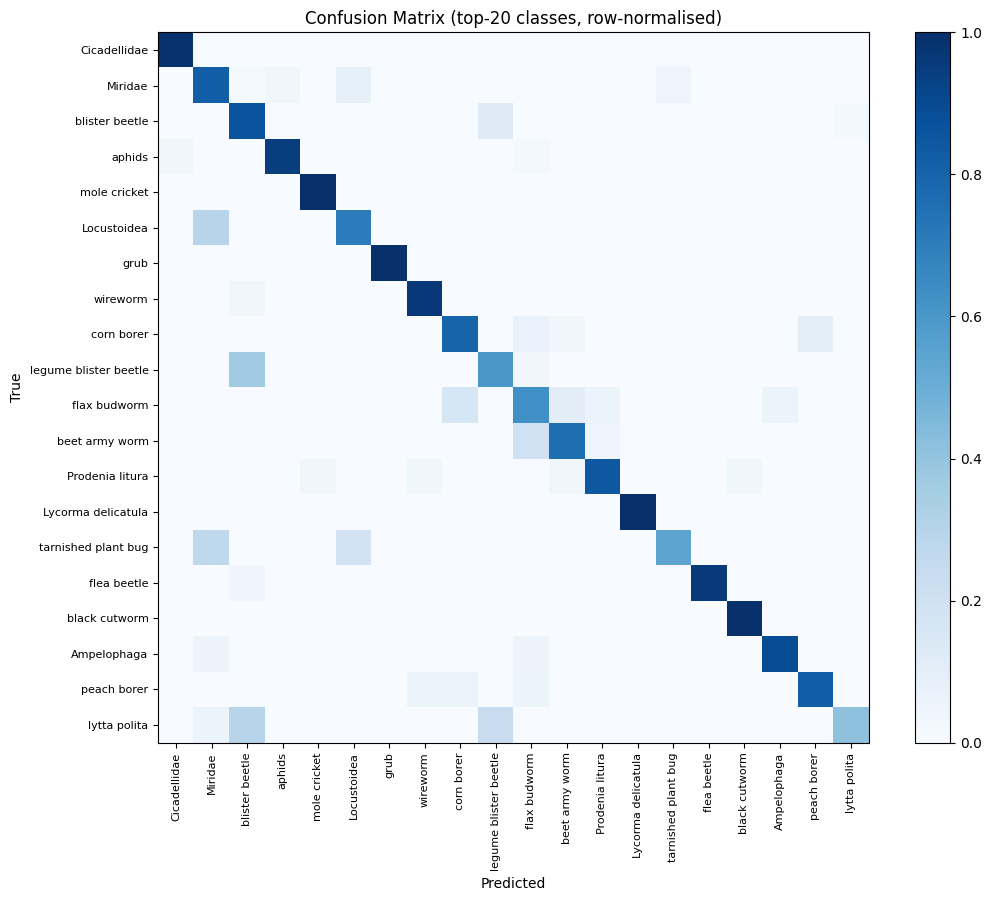

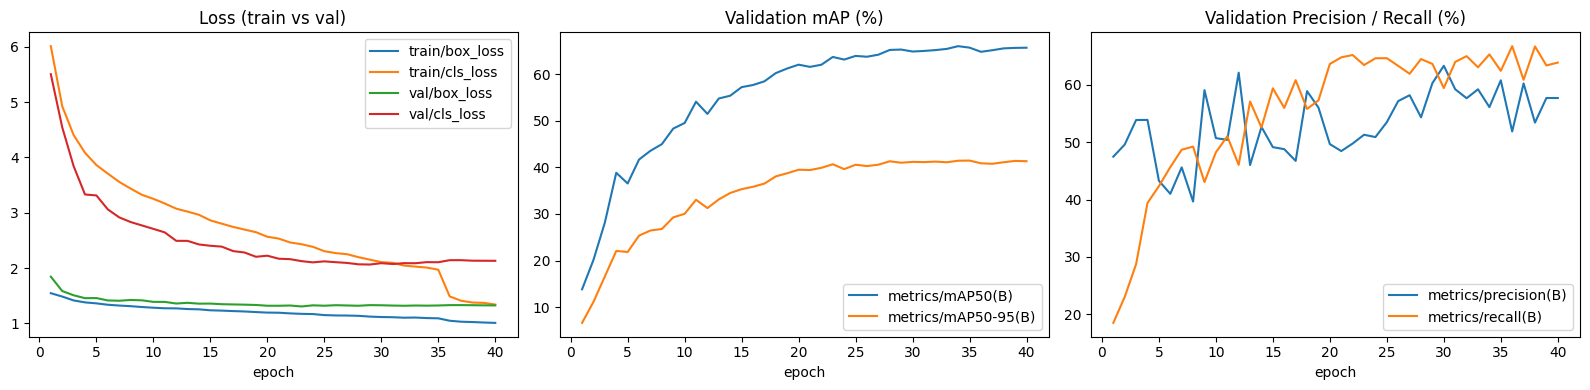


  IP102 INSECT PEST DETECTION - EVALUATION METRICS
  1. Accuracy - Training (image-level, 1500 img sample)      89.93 %
  1. Accuracy - Validation (image-level)                     74.34 %
  2. Precision - image-level (weighted / macro)              73.94 % / 62.07 %
  2. Precision - detection-level (IoU>=0.5)                  68.51 %
  3. Recall - image-level (weighted / macro)                 74.34 % / 58.52 %
  3. Recall - detection-level (IoU>=0.5)                     73.29 %
  4. F1-Score - detection-level (overall)                    70.82 %
  5. Macro F1 - image-level / detection-level                58.62 % / 56.87 %
  6. Weighted F1 - image-level / detection-level             73.17 % / 69.94 %
  7. mAP@0.50 / mAP@0.50:0.95                                65.33 % / 41.18 %
  8. Average Precision (AP) - see per_class_AP.csv           best: Rice Stemfly 99.5% | worst: alfalfa seed chalcid 3.3%
  9. IoU - mean of matched boxes / mean best-IoU per GT      0.811 / 0.742
  10. Confus

In [17]:
# Cell 10: IP102 Insect Pest Detection - Evaluation Metrics (all 12)
import time, json, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.ops import box_iou
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, confusion_matrix)
from ultralytics import YOLO

# ---------- load trained weights ----------
_a = OUTPUT_DIR / "best.pt"
_b = Path(TRAIN_CONFIG["project"]) / TRAIN_CONFIG["name"] / "weights" / "best.pt"
WEIGHTS = _a if _a.exists() else _b
assert WEIGHTS.exists(), "best.pt ledu - Cell 7 (training) munduga run cheyyi."
model = YOLO(str(WEIGHTS))
IMGSZ = TRAIN_CONFIG["imgsz"]
nc = num_classes
CONF_DET, IOU_T = 0.25, 0.5
USE_HALF = torch.cuda.is_available()

def read_gt(f):
    out = []
    if f.exists():
        for l in f.read_text().splitlines():
            p = l.split()
            if len(p) == 5:
                out.append((int(float(p[0])), *map(float, p[1:])))
    return out

def evaluate_split(img_paths, lbl_dir, bs=32):
    y_true, y_pred = [], []
    tp, fp, fn = np.zeros(nc), np.zeros(nc), np.zeros(nc)
    tp_ious, best_ious = [], []
    for s in range(0, len(img_paths), bs):
        chunk = img_paths[s:s + bs]
        res = model.predict([str(p) for p in chunk], conf=0.05, imgsz=IMGSZ, verbose=False, half=USE_HALF)
        for p, r in zip(chunk, res):
            gt = read_gt(lbl_dir / (p.stem + ".txt"))
            if not gt:
                continue
            H, W = r.orig_shape
            g_cls = torch.tensor([g[0] for g in gt])
            g_box = torch.tensor([[(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]
                                  for _, xc, yc, w, h in gt])
            gset = set(g_cls.tolist())
            # ---- image-level: highest-confidence box = predicted pest
            pred = -1 if len(r.boxes) == 0 else int(r.boxes.cls[r.boxes.conf.argmax()].item())
            primary = max(gset, key=lambda c: int((g_cls == c).sum()))
            y_true.append(pred if pred in gset else primary)
            y_pred.append(pred)
            # ---- detection-level matching (IoU >= 0.5, same class)
            keep = r.boxes.conf >= CONF_DET
            pb, pc, ps = r.boxes.xyxy[keep].cpu(), r.boxes.cls[keep].cpu().long(), r.boxes.conf[keep].cpu()
            matched = torch.zeros(len(gt), dtype=torch.bool)
            if len(pb):
                ious = box_iou(pb, g_box)
                best_ious.extend(ious.max(0).values.tolist())
                for i in ps.argsort(descending=True).tolist():
                    cand = ious[i].clone()
                    cand[(g_cls != pc[i]) | matched] = -1
                    j = int(cand.argmax())
                    if cand[j] >= IOU_T:
                        matched[j] = True; tp[int(pc[i])] += 1; tp_ious.append(float(cand[j]))
                    else:
                        fp[int(pc[i])] += 1
            else:
                best_ious.extend([0.0] * len(gt))
            for j in range(len(gt)):
                if not matched[j]:
                    fn[int(g_cls[j])] += 1
    return dict(y_true=np.array(y_true), y_pred=np.array(y_pred), tp=tp, fp=fp, fn=fn,
                tp_ious=tp_ious, best_ious=best_ious)

def img_list(d):
    return sorted([p for p in d.iterdir() if p.suffix in IMG_EXTENSIONS])

val_imgs = img_list(dataset_paths["images_val"])
random.seed(SEED)
tr_all = img_list(dataset_paths["images_train"])
tr_imgs = random.sample(tr_all, min(1500, len(tr_all)))      # 1500-image sample = fast

print("Evaluating validation images...")
V = evaluate_split(val_imgs, dataset_paths["labels_val"])
print("Evaluating training sample (1500 images)...")
T = evaluate_split(tr_imgs, dataset_paths["labels_train"])

# ---------- 1. ACCURACY (image-level top-1) ----------
acc_val = 100 * accuracy_score(V["y_true"], V["y_pred"])
acc_tr = 100 * accuracy_score(T["y_true"], T["y_pred"])

# ---------- 2-6, 11. image-level P / R / F1 / macro / weighted / kappa ----------
labs = sorted(set(V["y_true"].tolist()))
P_w = 100 * precision_score(V["y_true"], V["y_pred"], labels=labs, average="weighted", zero_division=0)
R_w = 100 * recall_score(V["y_true"], V["y_pred"], labels=labs, average="weighted", zero_division=0)
P_m = 100 * precision_score(V["y_true"], V["y_pred"], labels=labs, average="macro", zero_division=0)
R_m = 100 * recall_score(V["y_true"], V["y_pred"], labels=labs, average="macro", zero_division=0)
F1_w = 100 * f1_score(V["y_true"], V["y_pred"], labels=labs, average="weighted", zero_division=0)
F1_m = 100 * f1_score(V["y_true"], V["y_pred"], labels=labs, average="macro", zero_division=0)
kappa = cohen_kappa_score(V["y_true"], V["y_pred"])

# ---------- detection-level P / R / F1 ----------
tp, fp, fn = V["tp"], V["fp"], V["fn"]
sup = tp + fn
with np.errstate(divide="ignore", invalid="ignore"):
    dp = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
    dr = np.where(tp + fn > 0, tp / (tp + fn), 0.0)
    df1 = np.where(dp + dr > 0, 2 * dp * dr / (dp + dr), 0.0)
has = sup > 0
det_P, det_R = 100 * tp.sum() / max(tp.sum() + fp.sum(), 1), 100 * tp.sum() / max(tp.sum() + fn.sum(), 1)
det_F1 = 2 * det_P * det_R / max(det_P + det_R, 1e-9)
det_macroF1 = 100 * df1[has].mean()
det_weightedF1 = 100 * (df1 * sup).sum() / sup.sum()

# ---------- 7-8. mAP & per-class AP (official Ultralytics validation) ----------
vr = model.val(data=str(runtime_yaml_path), split="val", imgsz=IMGSZ, batch=32, conf=0.001,
               plots=True, verbose=False, project=str(OUTPUT_DIR / "runs"), name="final_val", exist_ok=True)
map50, map5095 = 100 * vr.box.map50, 100 * vr.box.map
ap_df = pd.DataFrame({"class_id": vr.box.ap_class_index,
                      "class": [class_names[i] for i in vr.box.ap_class_index],
                      "AP50": 100 * vr.box.ap50,
                      "AP50-95": 100 * vr.box.ap}).sort_values("AP50", ascending=False)
ap_df.to_csv(OUTPUT_DIR / "per_class_AP.csv", index=False)

# ---------- 9. IoU ----------
mean_iou_tp = float(np.mean(V["tp_ious"])) if V["tp_ious"] else 0.0
mean_iou_gt = float(np.mean(V["best_ious"])) if V["best_ious"] else 0.0

# ---------- 12. Inference time ----------
sample = [str(p) for p in val_imgs[:105]]
for p in sample[:5]:
    model.predict(p, imgsz=IMGSZ, verbose=False, half=USE_HALF)
times = []
for p in sample[5:]:
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t = time.perf_counter()
    model.predict(p, imgsz=IMGSZ, verbose=False, half=USE_HALF)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    times.append((time.perf_counter() - t) * 1000)
inf_ms = float(np.mean(times))

# ---------- 10. Confusion matrix (top-20 classes by support) ----------
cm_full = confusion_matrix(V["y_true"], V["y_pred"], labels=list(range(-1, nc)))
pd.DataFrame(cm_full, index=["bg"] + class_names, columns=["bg"] + class_names).to_csv(OUTPUT_DIR / "confusion_matrix_full.csv")
top = pd.Series(V["y_true"]).value_counts().index[:20].tolist()
cm = confusion_matrix(V["y_true"], V["y_pred"], labels=top)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top)))
ax.set_xticklabels([class_names[c] for c in top], rotation=90, fontsize=8)
ax.set_yticklabels([class_names[c] for c in top], fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix (top-20 classes, row-normalised)")
plt.colorbar(im); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrix_top20.png", dpi=200); plt.show()

# ---------- training / validation curves ----------
csv = Path(TRAIN_CONFIG["project"]) / TRAIN_CONFIG["name"] / "results.csv"
if csv.exists():
    rc = pd.read_csv(csv); rc.columns = [c.strip() for c in rc.columns]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for k in ["train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"]:
        if k in rc: ax[0].plot(rc["epoch"], rc[k], label=k)
    ax[0].set_title("Loss (train vs val)"); ax[0].legend(); ax[0].set_xlabel("epoch")
    for k in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        if k in rc: ax[1].plot(rc["epoch"], 100 * rc[k], label=k)
    ax[1].set_title("Validation mAP (%)"); ax[1].legend(); ax[1].set_xlabel("epoch")
    for k in ["metrics/precision(B)", "metrics/recall(B)"]:
        if k in rc: ax[2].plot(rc["epoch"], 100 * rc[k], label=k)
    ax[2].set_title("Validation Precision / Recall (%)"); ax[2].legend(); ax[2].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=200); plt.show()

# ---------- FINAL REPORT ----------
rows = [
 ("1. Accuracy - Training (image-level, 1500 img sample)", f"{acc_tr:.2f} %"),
 ("1. Accuracy - Validation (image-level)",               f"{acc_val:.2f} %"),
 ("2. Precision - image-level (weighted / macro)",        f"{P_w:.2f} % / {P_m:.2f} %"),
 ("2. Precision - detection-level (IoU>=0.5)",            f"{det_P:.2f} %"),
 ("3. Recall - image-level (weighted / macro)",           f"{R_w:.2f} % / {R_m:.2f} %"),
 ("3. Recall - detection-level (IoU>=0.5)",               f"{det_R:.2f} %"),
 ("4. F1-Score - detection-level (overall)",              f"{det_F1:.2f} %"),
 ("5. Macro F1 - image-level / detection-level",          f"{F1_m:.2f} % / {det_macroF1:.2f} %"),
 ("6. Weighted F1 - image-level / detection-level",       f"{F1_w:.2f} % / {det_weightedF1:.2f} %"),
 ("7. mAP@0.50 / mAP@0.50:0.95",                          f"{map50:.2f} % / {map5095:.2f} %"),
 ("8. Average Precision (AP) - see per_class_AP.csv",     f"best: {ap_df.iloc[0]['class']} {ap_df.iloc[0]['AP50']:.1f}% | worst: {ap_df.iloc[-1]['class']} {ap_df.iloc[-1]['AP50']:.1f}%"),
 ("9. IoU - mean of matched boxes / mean best-IoU per GT", f"{mean_iou_tp:.3f} / {mean_iou_gt:.3f}"),
 ("10. Confusion Matrix",                                  "saved: confusion_matrix_top20.png, confusion_matrix_full.csv"),
 ("11. Cohen's Kappa (image-level)",                       f"{kappa:.4f}"),
 ("12. Inference time / FPS (per image, 1 img batch)",     f"{inf_ms:.1f} ms / {1000/inf_ms:.1f} FPS  (Ultralytics val: {vr.speed['inference']:.1f} ms)"),
]
print("\n" + "=" * 92)
print("  IP102 INSECT PEST DETECTION - EVALUATION METRICS")
print("=" * 92)
for k, v in rows:
    print(f"  {k:<58} {v}")
print("=" * 92)
print(f"  Target validation accuracy >= 85% : {'REACHED' if acc_val >= 85 else 'NOT reached'}  (actual {acc_val:.2f}%)")
if acc_val < 85:
    print("  Next step: Cell 6 lo PROFILE = 'best' chesi malli run cheyyi (yolov8m, ekkuva accuracy).")
print("\nTop-5 classes by AP50:"); print(ap_df.head(5).to_string(index=False))
print("\nBottom-5 classes by AP50:"); print(ap_df.tail(5).to_string(index=False))

pd.DataFrame(rows, columns=["metric", "value"]).to_csv(OUTPUT_DIR / "final_metrics.csv", index=False)
json.dump({"val_accuracy": acc_val, "train_accuracy": acc_tr, "mAP50": map50, "mAP50_95": map5095,
           "macro_f1_image": F1_m, "weighted_f1_image": F1_w, "kappa": kappa, "inference_ms": inf_ms},
          open(OUTPUT_DIR / "final_metrics.json", "w"), indent=2)
